# Milestone 2 — Baseline Fault Detection

## Research question

Can we distinguish **Normal operation** from **Fault 4**, and how much of that distinction can be captured by a simple model and a small set of process variables?

This milestone has three goals:

1. Establish a transparent baseline for Normal-vs-Fault-4 classification.
2. Test whether a reduced feature set—especially `xmv_10`—retains useful predictive information.
3. Compare Logistic Regression with Random Forest on a chronological validation split, then explore whether a simple threshold could indicate fault onset.

**Important evaluation note.** The test sequences are useful for inspecting behavior, but test-set results must not guide model or threshold selection if they are to serve as an independent final evaluation. Earlier exploratory work already examined these test sequences, so any test results in this notebook are treated as diagnostics rather than a pristine, untouched final score. The validation split is the primary basis for model comparison.

## 1. Imports and experimental setup

We use the supplied Tennessee Eastman Process files. Each sample contains 52 variables: 41 measured variables (`xmeas_1`–`xmeas_41`) and 11 manipulated variables (`xmv_1`–`xmv_11`).

In [ ]:
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
FAULT_ONSET = 160

## 2. Load the data and verify the label convention

The key label distinction is known before constructing the arrays:

- `d00.dat` and `d00_te.dat` are Normal.
- The Fault 4 **training** sequence `d04.dat` is treated as Fault 4 throughout.
- The Fault 4 **test** sequence `d04_te.dat` contains an initial normal operating period; samples `0`–`159` are Normal and the fault begins at index `160`.

Therefore, we assign labels correctly once, at construction time. We do not create incorrect labels and then repair them later. The onset convention is checked visually as a sanity check, not used to discover the label rule from scratch.

In [ ]:
data_dir = Path("/content/tep_data")
if not data_dir.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/believe563/tennessee-eastman-profBraatz-database.git",
            str(data_dir),
        ],
        check=True,
    )

variable_names = (
    [f"xmeas_{i}" for i in range(1, 42)]
    + [f"xmv_{i}" for i in range(1, 12)]
)

def load_tep_data(filename, expected_variables=52):
    matches = list(data_dir.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"{filename} not found under {data_dir}")

    data = np.loadtxt(matches[0])
    if data.ndim != 2:
        raise ValueError(f"Expected 2D data in {filename}; got {data.shape}")
    if data.shape[1] == expected_variables:
        pass
    elif data.shape[0] == expected_variables:
        data = data.T
    else:
        raise ValueError(f"Unexpected shape {data.shape} in {filename}")

    return pd.DataFrame(data, columns=variable_names)

df_normal = load_tep_data("d00.dat")
df_fault4 = load_tep_data("d04.dat")
df_normal_test = load_tep_data("d00_te.dat")
df_fault4_test = load_tep_data("d04_te.dat")

for name, frame in [
    ("Normal train", df_normal),
    ("Fault 4 train", df_fault4),
    ("Normal test", df_normal_test),
    ("Fault 4 test", df_fault4_test),
]:
    print(f"{name:15s}: {frame.shape}")

assert all(frame.shape[1] == 52 for frame in [
    df_normal, df_fault4, df_normal_test, df_fault4_test
])
assert len(df_fault4_test) > FAULT_ONSET

Normal train   : (500, 52)
Fault 4 train  : (480, 52)
Normal test    : (960, 52)
Fault 4 test   : (960, 52)


### Sanity check: inspect the Fault 4 test sequence

The plot checks whether the sequence changes around the documented onset. The visual pattern is a diagnostic cross-check; the known label convention, rather than visual guesswork, determines the labels.

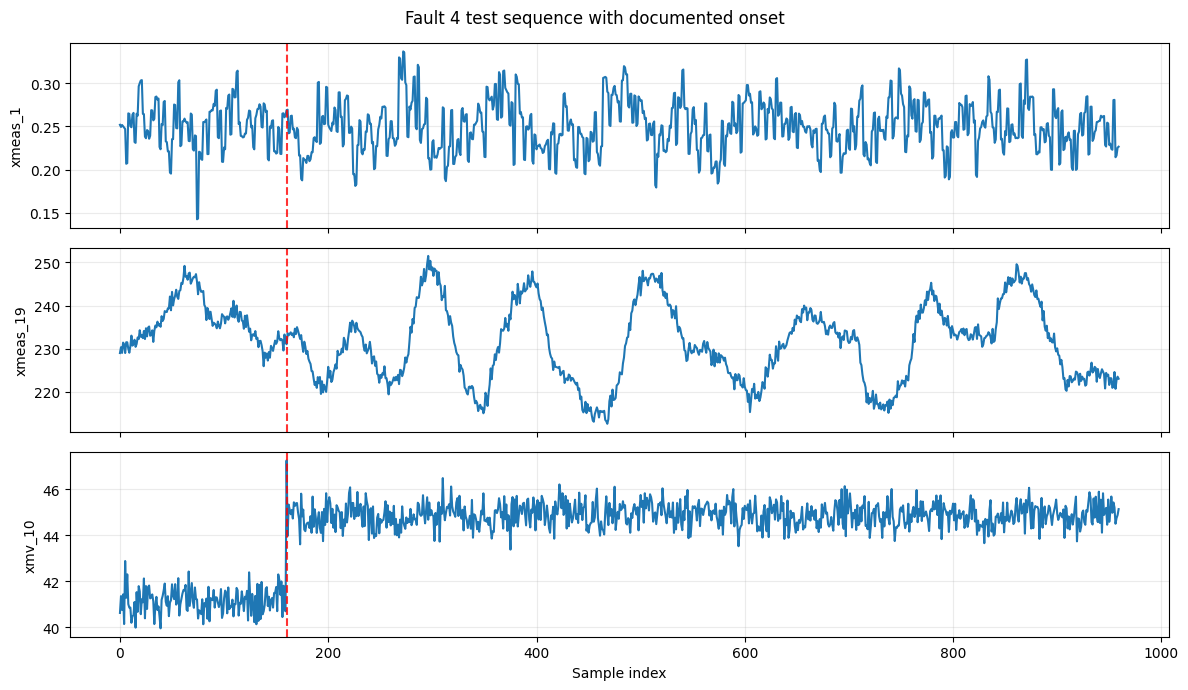

In [ ]:
variables_to_plot = ["xmeas_1", "xmeas_19", "xmv_10"]
fig, axes = plt.subplots(len(variables_to_plot), 1, figsize=(12, 7), sharex=True)

for ax, variable in zip(axes, variables_to_plot):
    ax.plot(df_fault4_test[variable].to_numpy())
    ax.axvline(FAULT_ONSET, color="red", linestyle="--", alpha=0.8)
    ax.set_ylabel(variable)
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Sample index")
fig.suptitle("Fault 4 test sequence with documented onset")
plt.tight_layout()
plt.show()

## 3. Construct features and labels once

The training set is built from the training files. For the test set, the first 160 samples of `d04_te.dat` are labeled Normal and the remaining samples Fault 4. This avoids the label-repair step that made the earlier workflow confusing.

We split the training sequences chronologically **before fitting models**. This gives us a validation set for model and feature comparisons without repeatedly using the test set to make decisions.

In [ ]:
X_train = pd.concat([df_normal, df_fault4], ignore_index=True)
y_train = np.concatenate([
    np.zeros(len(df_normal), dtype=int),
    np.ones(len(df_fault4), dtype=int),
])

X_test = pd.concat([df_normal_test, df_fault4_test], ignore_index=True)
y_normal_test = np.zeros(len(df_normal_test), dtype=int)
y_fault4_test = np.ones(len(df_fault4_test), dtype=int)
y_fault4_test[:FAULT_ONSET] = 0
y_test = np.concatenate([y_normal_test, y_fault4_test])

normal_cut = int(len(df_normal) * 0.8)
fault_cut = int(len(df_fault4) * 0.8)

X_fit = pd.concat([
    df_normal.iloc[:normal_cut],
    df_fault4.iloc[:fault_cut],
], ignore_index=True)
y_fit = np.concatenate([
    np.zeros(normal_cut, dtype=int),
    np.ones(fault_cut, dtype=int),
])

X_val = pd.concat([
    df_normal.iloc[normal_cut:],
    df_fault4.iloc[fault_cut:],
], ignore_index=True)
y_val = np.concatenate([
    np.zeros(len(df_normal) - normal_cut, dtype=int),
    np.ones(len(df_fault4) - fault_cut, dtype=int),
])

def print_split(name, X, y):
    counts = pd.Series(y).value_counts().sort_index().to_dict()
    print(f"{name:12s}: X={X.shape}, class counts (0=Normal, 1=Fault 4)={counts}")

print_split("Full train", X_train, y_train)
print_split("Fit", X_fit, y_fit)
print_split("Validation", X_val, y_val)
print_split("Test (exploratory)", X_test, y_test)

Full train  : X=(980, 52), class counts (0=Normal, 1=Fault 4)={0: 500, 1: 480}
Fit         : X=(784, 52), class counts (0=Normal, 1=Fault 4)={0: 400, 1: 384}
Validation  : X=(196, 52), class counts (0=Normal, 1=Fault 4)={0: 100, 1: 96}
Test (exploratory): X=(1920, 52), class counts (0=Normal, 1=Fault 4)={0: 1120, 1: 800}


## 4. Establish a full-feature baseline

Logistic Regression is the first baseline: it is relatively simple, and its standardized coefficients can help generate hypotheses about influential variables. We fit it only on the chronological fitting portion and use validation for the primary score.

The test set is not used here to choose the model.

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression (52 features),1.0,1.0,1.0,1.0


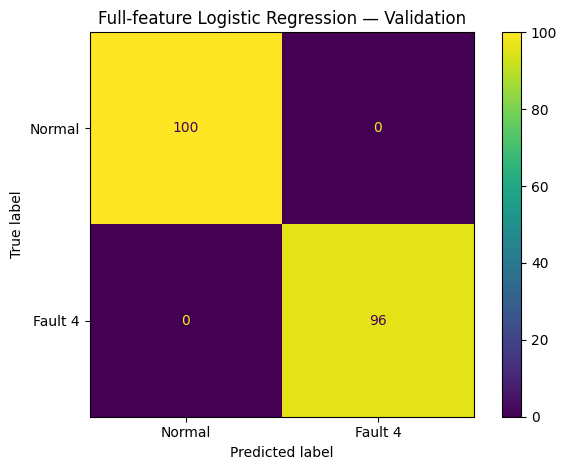

In [ ]:
def make_logistic_regression():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE,
        )),
    ])

baseline_model = make_logistic_regression()
baseline_model.fit(X_fit, y_fit)
val_pred_full = baseline_model.predict(X_val)

def binary_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

baseline_metrics = binary_metrics(y_val, val_pred_full)
display(pd.DataFrame([{"Model": "Logistic Regression (52 features)", **baseline_metrics}]).round(4))

ConfusionMatrixDisplay.from_predictions(
    y_val, val_pred_full, labels=[0, 1],
    display_labels=["Normal", "Fault 4"], values_format="d"
)
plt.title("Full-feature Logistic Regression — Validation")
plt.tight_layout()
plt.show()

### What does the baseline suggest?

The validation result tells us how well the full-feature linear baseline separates the two classes. We next inspect its standardized coefficients to identify candidate variables, then test the `xmv_10` hypothesis directly on the same fit/validation split.

Coefficient magnitude is a **model-dependent association**, not proof of physical causation. Because correlated features can share or redistribute coefficients, the single-feature experiment is needed before concluding that one variable alone is sufficient.

,Variable,Coefficient,AbsCoefficient
0,xmv_10,5.3438,5.3438
1,xmeas_9,-0.5452,0.5452
2,xmeas_21,0.2683,0.2683
3,xmeas_35,-0.1749,0.1749
4,xmeas_39,-0.1564,0.1564
5,xmeas_20,0.1440,0.1440
6,xmeas_27,0.1069,0.1069
7,xmeas_18,0.1052,0.1052
8,xmeas_34,0.1017,0.1017
9,xmv_1,-0.1014,0.1014


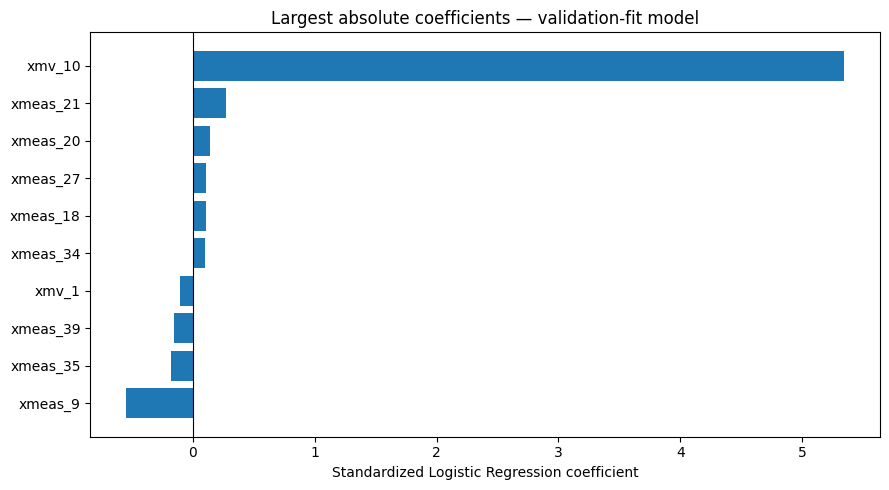

In [ ]:
classifier = baseline_model.named_steps["classifier"]
coef_df = pd.DataFrame({
    "Variable": X_fit.columns,
    "Coefficient": classifier.coef_[0],
})
coef_df["AbsCoefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("AbsCoefficient", ascending=False).reset_index(drop=True)
display(coef_df.head(10).round(4))

top_coef = coef_df.head(10).sort_values("Coefficient")
plt.figure(figsize=(9, 5))
plt.barh(top_coef["Variable"], top_coef["Coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Standardized Logistic Regression coefficient")
plt.title("Largest absolute coefficients — validation-fit model")
plt.tight_layout()
plt.show()

## 5. Test the `xmv_10` hypothesis

The coefficient analysis motivates a focused comparison: does a Logistic Regression model using only `xmv_10` retain most of the validation performance of the 52-feature baseline?

This is the central feature-reduction experiment. We compare both models on exactly the same validation samples and summarize their metrics in one table.

,Model,Accuracy,Precision,Recall,F1
0,All 52 variables,1.0,1.0,1.0,1.0
1,xmv_10 only,1.0,1.0,1.0,1.0


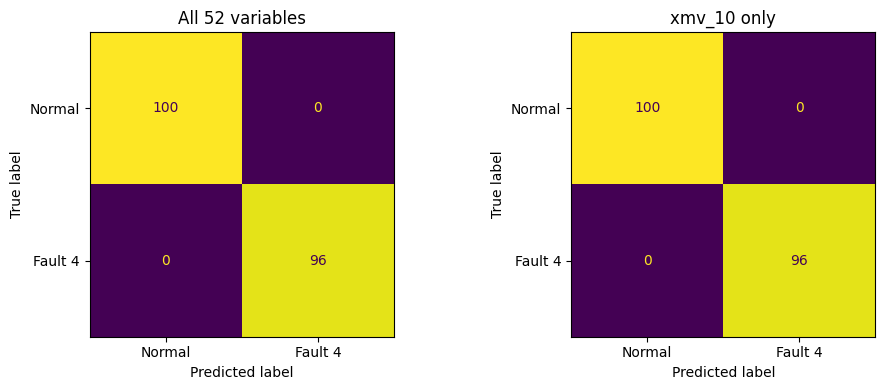

In [ ]:
single_feature_model = make_logistic_regression()
single_feature_model.fit(X_fit[["xmv_10"]], y_fit)
val_pred_single = single_feature_model.predict(X_val[["xmv_10"]])

feature_comparison = pd.DataFrame([
    {"Model": "All 52 variables", **binary_metrics(y_val, val_pred_full)},
    {"Model": "xmv_10 only", **binary_metrics(y_val, val_pred_single)},
])
display(feature_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in [
    (axes[0], val_pred_full, "All 52 variables"),
    (axes[1], val_pred_single, "xmv_10 only"),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_val, pred, labels=[0, 1],
        display_labels=["Normal", "Fault 4"],
        values_format="d", ax=ax, colorbar=False,
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

### Interpretation

If the single-feature model is close to the full-feature baseline, `xmv_10` may capture much of the signal in this particular Normal-vs-Fault-4 task. If it is worse, the other variables add useful information. Either way, this comparison is more informative than repeatedly plotting the same feature without testing a new question.

The next plot is a single, compact view of `xmv_10` over time in the Normal and Fault 4 training sequences. It is used to interpret the feature result, not as another independent model evaluation.

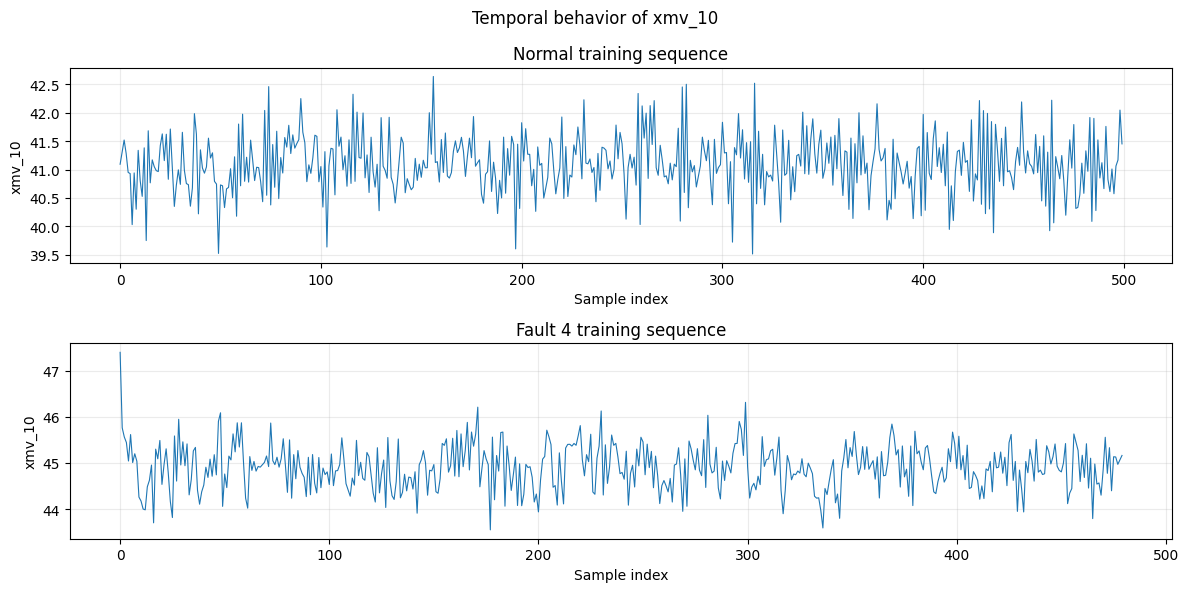

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=False)
axes[0].plot(df_normal["xmv_10"].to_numpy(), linewidth=0.8)
axes[0].set_title("Normal training sequence")
axes[0].set_ylabel("xmv_10")
axes[0].set_xlabel("Sample index")
axes[0].grid(alpha=0.25)

axes[1].plot(df_fault4["xmv_10"].to_numpy(), linewidth=0.8)
axes[1].set_title("Fault 4 training sequence")
axes[1].set_ylabel("xmv_10")
axes[1].set_xlabel("Sample index")
axes[1].grid(alpha=0.25)

plt.suptitle("Temporal behavior of xmv_10")
plt.tight_layout()
plt.show()

## 6. Compare feature groups and model families

The previous experiment asked whether `xmv_10` alone can work. We now ask two broader questions in one controlled comparison:

- Do measured variables (`xmeas`), manipulated variables (`xmv`), or all 52 variables provide the most useful validation signal?
- Does Random Forest improve on Logistic Regression for these feature groups?

All six combinations use the same chronological fit/validation split. This replaces separate, overlapping comparison sections with one table, so the role of each feature group and model family can be assessed together.

In [ ]:
xmeas_cols = [f"xmeas_{i}" for i in range(1, 42)]
xmv_cols = [f"xmv_{i}" for i in range(1, 12)]
all_cols = xmeas_cols + xmv_cols

feature_groups = {
    "Measured only (41)": xmeas_cols,
    "Manipulated only (11)": xmv_cols,
    "All variables (52)": all_cols,
    "xmv_10 only (1)": ["xmv_10"],
}

def make_random_forest():
    return RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        min_samples_leaf=2,
        n_jobs=-1,
    )

model_factories = {
    "Logistic Regression": make_logistic_regression,
    "Random Forest": make_random_forest,
}

comparison_rows = []
for group_name, columns in feature_groups.items():
    for model_name, make_model in model_factories.items():
        model = make_model()
        model.fit(X_fit[columns], y_fit)
        prediction = model.predict(X_val[columns])
        comparison_rows.append({
            "Feature group": group_name,
            "Model": model_name,
            **binary_metrics(y_val, prediction),
        })

model_comparison = pd.DataFrame(comparison_rows)
display(
    model_comparison.sort_values(["Feature group", "Model"])
    .reset_index(drop=True).round(4)
)

,Feature group,Model,Accuracy,Precision,Recall,F1
0,All variables (52),Logistic Regression,1.0000,1.000,1.0000,1.0000
1,All variables (52),Random Forest,1.0000,1.000,1.0000,1.0000
2,Manipulated only (11),Logistic Regression,1.0000,1.000,1.0000,1.0000
3,Manipulated only (11),Random Forest,1.0000,1.000,1.0000,1.0000
4,Measured only (41),Logistic Regression,0.4337,0.400,0.3125,0.3509
5,Measured only (41),Random Forest,0.3469,0.314,0.2812,0.2967
6,xmv_10 only (1),Logistic Regression,1.0000,1.000,1.0000,1.0000
7,xmv_10 only (1),Random Forest,1.0000,1.000,1.0000,1.0000


### How to read this comparison

This table is the main model-comparison result for Milestone 2. It shows whether a more complex model or a broader feature set improves validation performance. The best result on this one split should not be treated as proof of universal superiority; it is evidence for the next stage of investigation.

We do not run a separate one-variable leaderboard for all 11 manipulated variables here. That additional ranking is only worth adding if the project needs to identify the best manipulated variable beyond the already motivated `xmv_10` hypothesis.

## 7. Exploratory threshold-based onset detection

Classification asks whether a sample looks Normal or faulty. Onset detection asks a different practical question: **how soon after the transition can a simple rule raise an alarm, and does it also alarm during the available Normal test sequence?**

For an exploratory demonstration, we use the observed gap in `xmv_10` values around the Fault 4 test onset to define a midpoint threshold. This is deliberately labeled **exploratory** because the threshold is derived from the same test sequence on which its behavior is demonstrated. It is not an independent estimate of real-world detection performance.

Maximum xmv_10 before onset: 42.8790
Minimum xmv_10 after onset:  43.3740
Exploratory midpoint threshold: 43.1265


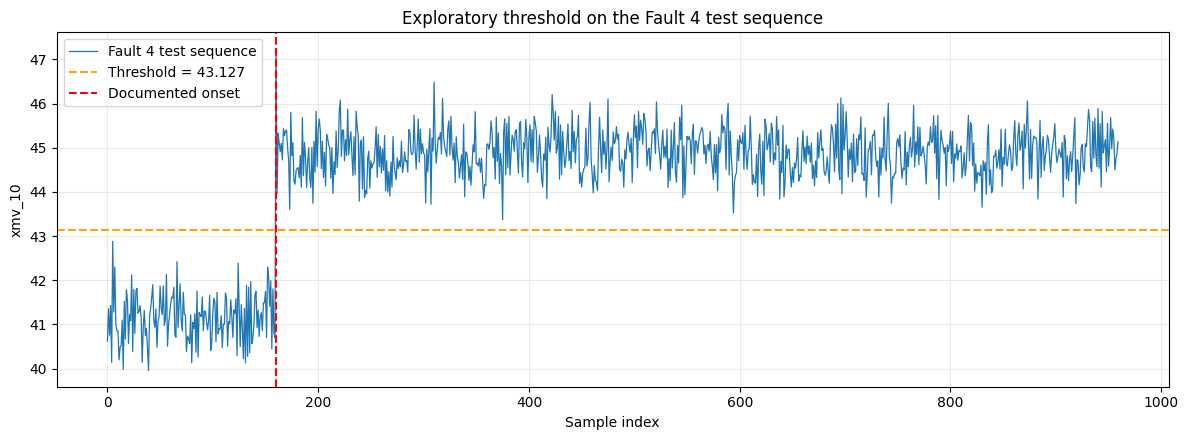

In [ ]:
x_fault_test = df_fault4_test["xmv_10"].to_numpy()
x_normal_test = df_normal_test["xmv_10"].to_numpy()

before = x_fault_test[:FAULT_ONSET]
after = x_fault_test[FAULT_ONSET:]
threshold = (before.max() + after.min()) / 2

print(f"Maximum xmv_10 before onset: {before.max():.4f}")
print(f"Minimum xmv_10 after onset:  {after.min():.4f}")
print(f"Exploratory midpoint threshold: {threshold:.4f}")

plt.figure(figsize=(12, 4.5))
plt.plot(x_fault_test, linewidth=0.9, label="Fault 4 test sequence")
plt.axhline(threshold, color="orange", linestyle="--", label=f"Threshold = {threshold:.3f}")
plt.axvline(FAULT_ONSET, color="red", linestyle="--", label="Documented onset")
plt.xlabel("Sample index")
plt.ylabel("xmv_10")
plt.title("Exploratory threshold on the Fault 4 test sequence")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Detection delay and false-alarm check

We compare two simple alarm rules: (A) one sample above threshold and (B) three consecutive samples above threshold. The same rules are applied to the available Normal test sequence to check for false alarms. These results describe only the sequences examined; they do not establish generalization to unseen operating conditions.

In [ ]:
def first_consecutive_run(values, threshold_value, required=1, start=0):
    above = np.asarray(values) > threshold_value
    for idx in range(start, len(above) - required + 1):
        if above[idx:idx + required].all():
            return idx
    return None

delay_rows = []
for rule_name, required in [("Single crossing", 1), ("3 consecutive crossings", 3)]:
    detection_idx = first_consecutive_run(
        x_fault_test, threshold, required=required, start=FAULT_ONSET
    )
    delay_rows.append({
        "Rule": rule_name,
        "Detection index": detection_idx,
        "Delay (samples)": None if detection_idx is None else detection_idx - FAULT_ONSET,
        "False alarm on Normal test?": (
            first_consecutive_run(x_normal_test, threshold, required=required) is not None
        ),
    })

display(pd.DataFrame(delay_rows))

,Rule,Detection index,Delay (samples),False alarm on Normal test?
0,Single crossing,160,0,False
1,3 consecutive crossings,160,0,False


## 8. Milestone 2 conclusions

### What this milestone can establish

- A Logistic Regression baseline provides a reference point for Normal-vs-Fault-4 classification.
- The validation comparison tests whether `xmv_10` alone retains useful information and whether measured/manipulated feature groups or Random Forest change performance.
- The `xmv_10` time-series and threshold demonstration provide an interpretable hypothesis for a possible onset signal.

### What it cannot yet establish

- A high score on these particular sequences does not guarantee performance on new process runs.
- A large coefficient or strong separation does not prove that `xmv_10` physically causes Fault 4.
- The threshold demonstration is exploratory because it uses the examined test sequence to set the threshold.
- Because the test sequences were already explored during development, their metrics should not be presented as an untouched final evaluation.

### Next research question — Milestone 3

Can we extend from a binary Normal-vs-Fault-4 task to **multi-fault diagnosis**, where the model must distinguish Normal operation and several different fault types rather than detect one known fault?